#### Teoría de Circuitos II - UTN.BA

# Tarea Semanal 7
#### Autor: Rodríguez Silvosa, Martín
#### Docentes: LLamedo, Mariano ; Moharos, David

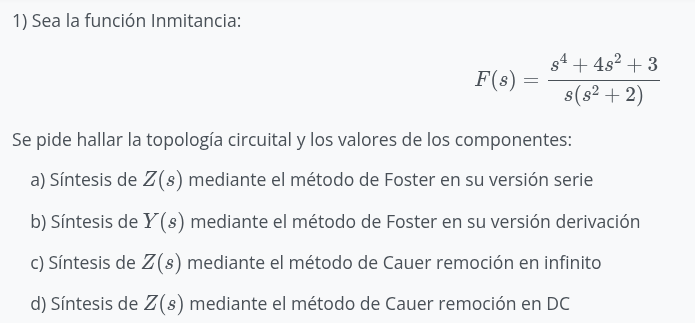

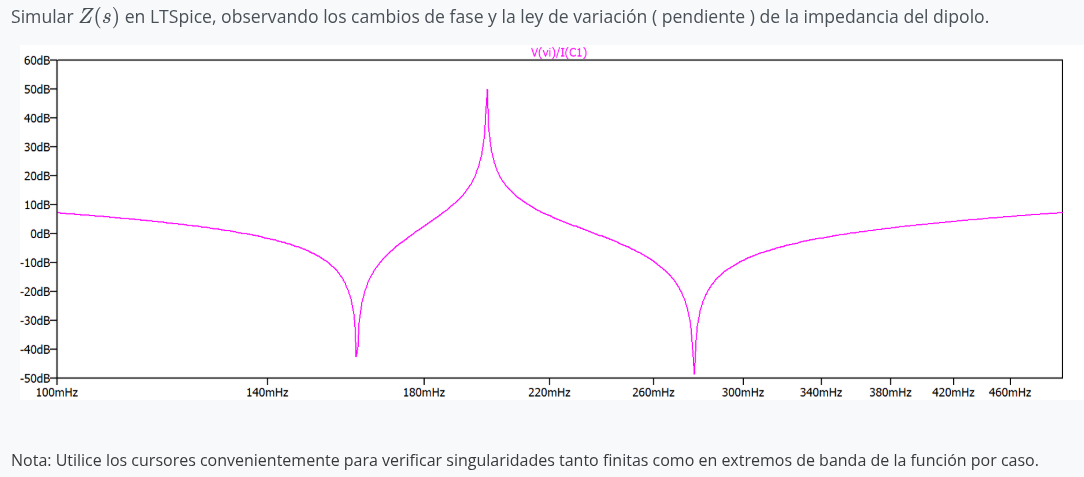

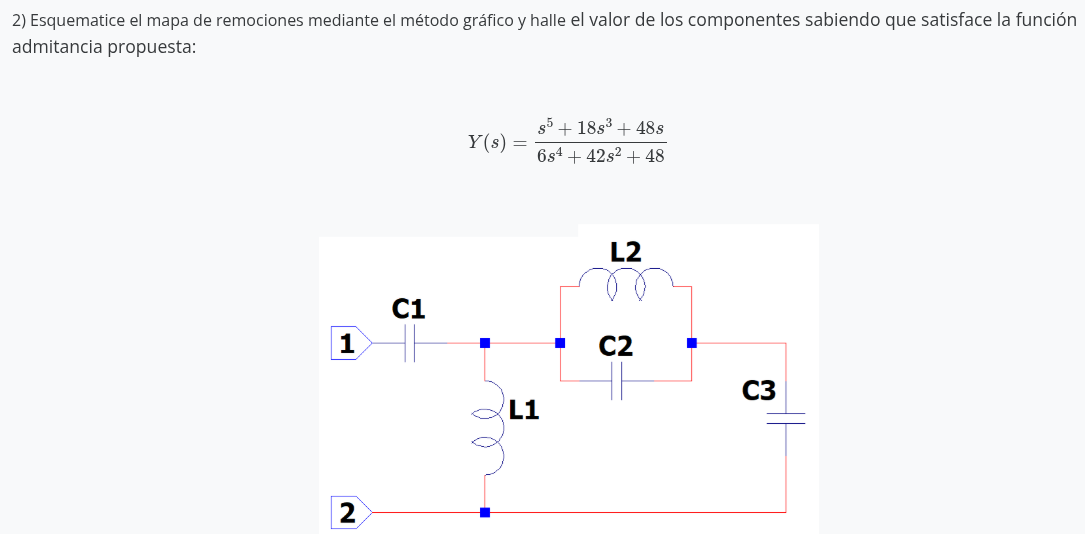

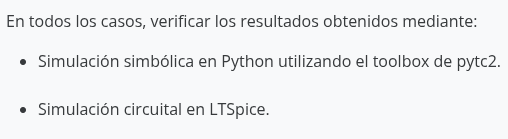

#### Librerías Python:

In [86]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from pytc2.remociones import remover_polo_dc
from pytc2.general import a_equal_b_latex_s, print_latex, s, symbfunc2tf, factorSOS
from pytc2.sistemas_lineales import bodePlot
from scipy import signal as sig

## Síntesis Foster Serie:

$$
F(s)= \frac{s^4+4s^2+3}{s(s^2+2)}
$$

### Método de expansión fracciones simples:
$$
F(s)= \frac{s^4+4s^2+3}{s(s^2+2)} = \frac{(s^2+1)(s^2+3)}{s(s^2+2)} = \frac{k_0}{s} + k_{\infty} \ s + \frac{2 \ k_1 \ s}{s^2+2}  
$$

### Residuos:
$$
k_0 : \ lim_{s\rightarrow 0} \ F(s) \cdot s = \frac{0 + 4 \cdot 0 + 3}{(0 + 2)} = \frac{3}{2}
$$
$$
k_{\infty}: \ lim_{s\rightarrow \infty} \ \frac{F(s)}{s} = \frac{(s^2+1)(s^2+3)}{s^2(s^2+2)} = \frac{{\infty}^4}{{\infty}^4} = 1
$$
$$
2 \ k_1 : \ lim_{s^2\rightarrow -2} \ F(s) \cdot \frac{s^2+2}{s} = \frac{(s^2+1)(s^2+3)}{s^2} = \frac{(-2+1)(-2+3)}{-2} = \frac{1}{2}
$$

$$
F(s) = \frac{k_0}{s} + k_{\infty} \ s + \frac{2 \ k_1 \ s}{s^2+2} = \frac{1}{s \frac{2}{3}} + 1 \cdot s + \frac{1}{s \cdot 2 + \frac{1}{s \cdot \frac{1}{4}}}
$$

#### Foster serie: Z
$$
Z = R + \frac{1}{s \ C} + s \ L + \frac{1}{s \ C + \frac{1}{s \ L}}
$$

### Topología circuital resultante:

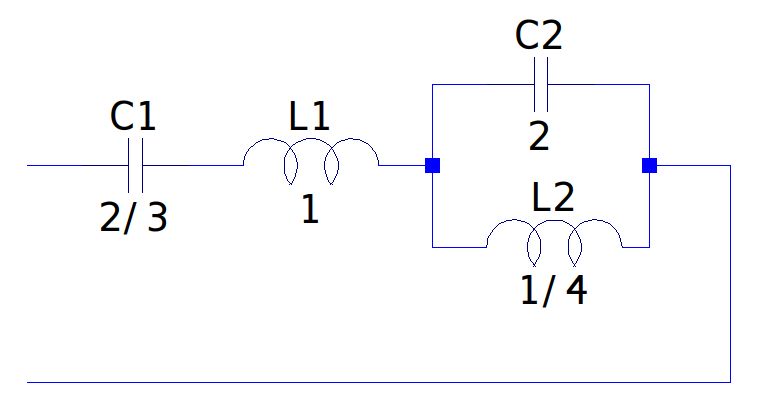

### Simulación observando fase y pendiente:
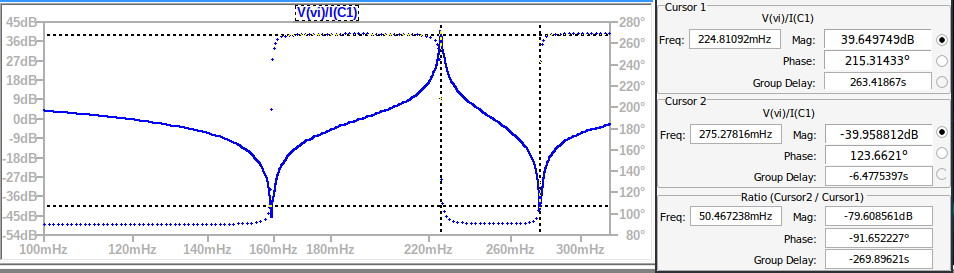

#### Singularidades vistas:
$$
Conversión: \ \ \omega = 2 \pi f \rightarrow f = \frac{\omega}{2 \pi}
$$

$$
cero \ en \ 160mHz \approx \omega = 1
$$
$$
polo \ en \ 224mHz \approx \omega = 1,407 \approx \sqrt{2}
$$
$$
cero \ en \ 275mHz \approx \omega = 1,727 \approx \sqrt{3}
$$
$$
polo \ en \ 0 \ tendencia \ visible
$$

#### En cada singularidad se ve un salto de fase de 180 grados, de 90º a 270º y viceversa entre ceros y polos.

## Síntesis Foster Derivación
#### Rescataremos los mismos resultados del Foster serie y los reinterpretaremos:

$$
F(s) = \frac{k_0}{s} + k_{\infty} \ s + \frac{2 \ k_1 \ s}{s^2+2} = \frac{1}{s \frac{2}{3}} + 1 \cdot s + \frac{1}{s \cdot 2 + \frac{1}{s \cdot \frac{1}{4}}}
$$

#### Foster derivación: Y
$$
Y = G + \frac{1}{s \ L} + s \ C + \frac{1}{s \ L + \frac{1}{s \ C}}
$$

### Topología circuital resultante:
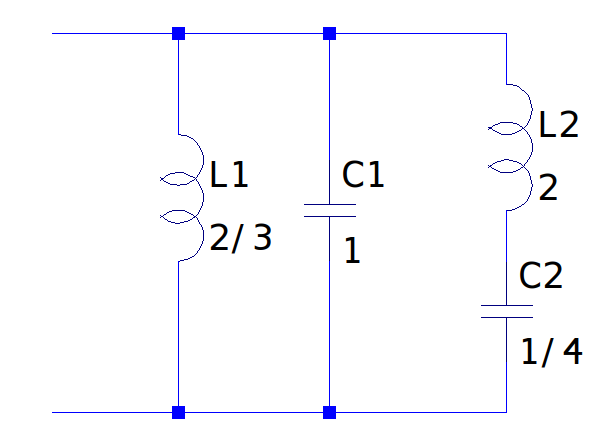

### Simulación observando fase y pendiente:
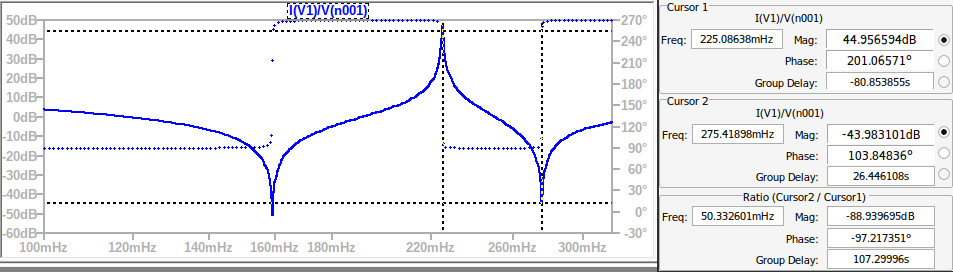

#### Se mide esta vez $I/V$ porque $F(s) = Y$. Se observan las mismas singularidades que en el anterior.

## Síntesis Z Cauer infinito:

$$
F(s)= \frac{s^4+4s^2+3}{s(s^2+2)} = \frac{s^4+4s^2+3}{s^3+2 \ s} 
$$

### Remociones en el infinito:

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


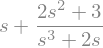

F resultante:


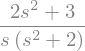

Próxima división:


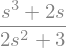

In [19]:
sp.init_printing()

s = sp.Symbol('s')

numerador = 1*s**4 + 4*s**2 + 3
denominador = 1*s**3 + 2*s

cociente, residuo = sp.div(numerador, denominador, s)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Inductor serie valor $1$;

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


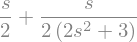

F resultante:


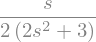

Próxima división:


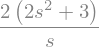

In [26]:
sp.init_printing()

s = sp.Symbol('s')

numerador = 1*s**3 + 2*s
denominador = 2*s**2 + 3

cociente, residuo = sp.div(numerador, denominador, s)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Capacitor derivación valor $\frac{1}{2}$;

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


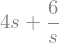

F resultante:


Próxima división:


In [31]:
sp.init_printing()

s = sp.Symbol('s')

numerador = 4*s**2 + 6
denominador = s

cociente, residuo = sp.div(numerador, denominador, s)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Inductor serie valor $4$;

In [37]:
sp.init_printing()

s = sp.Symbol('s')

numerador = s
denominador = 6

cociente, residuo = sp.div(numerador, denominador, s)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


F resultante:


### Capacitor derivación valor $\frac{1}{6}$;

## Procedemos a realizar el método gráfico removiendo polos en el infinito:

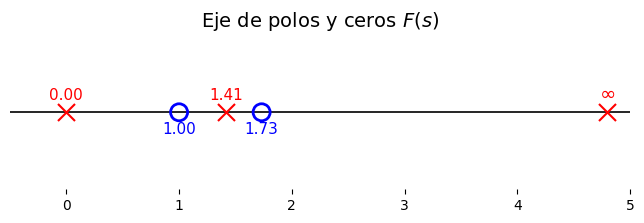

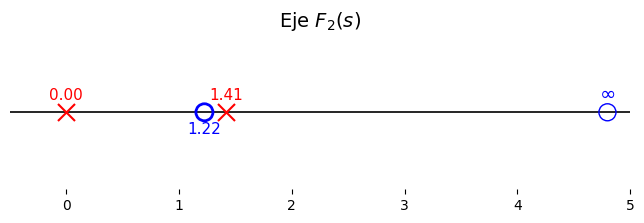

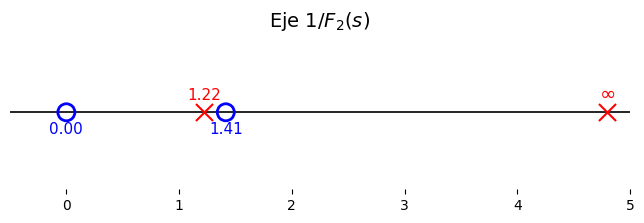

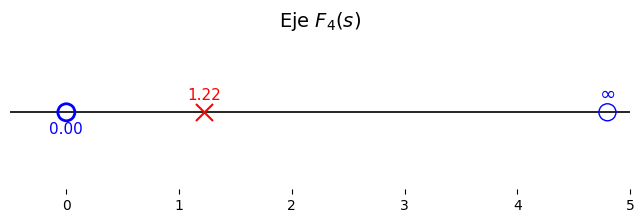

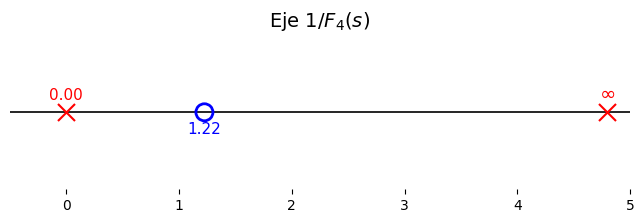

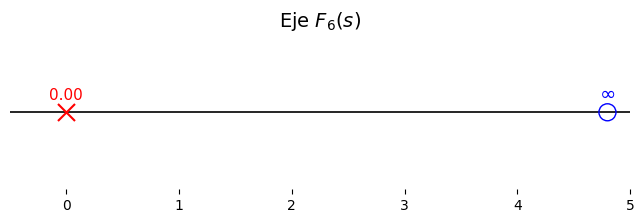

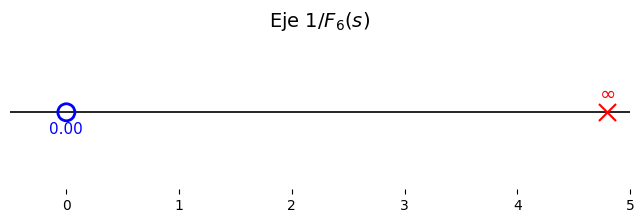

In [35]:
fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0, np.sqrt(2)]
ceros = [1, np.sqrt(3)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje de polos y ceros $F(s)$", fontsize=14)
plt.show()

##### eje 2: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0, np.sqrt(2)]
ceros = [np.sqrt(3/2)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_2(s)$", fontsize=14)
plt.show()

##### eje 2 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [0, np.sqrt(2)]
polos = [np.sqrt(3/2)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_2(s)$", fontsize=14)
plt.show()

##### eje 4: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [0]
polos = [np.sqrt(6/4)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_4(s)$", fontsize=14)
plt.show()

##### eje 4 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0]
ceros = [np.sqrt(6/4)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_4(s)$", fontsize=14)
plt.show()

##### eje 6: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0]
##ceros = [np.sqrt(6/4)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
##ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
##for c in ceros:
##    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_6(s)$", fontsize=14)
plt.show()

##### eje 6 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [0]
##polos = [np.sqrt(6/4)]

##ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

##for p in polos:
##    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_6(s)$", fontsize=14)
plt.show()


### Topología circuital resultante:
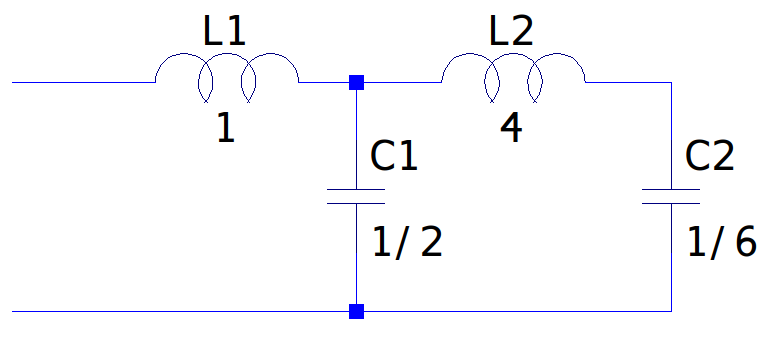

### Simulación observando fase y pendiente:
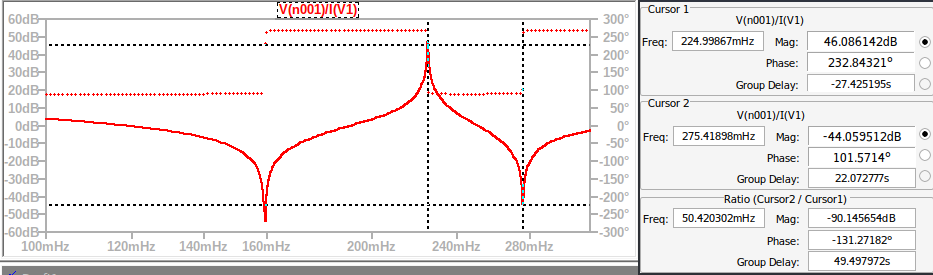

#### Se observa el mismo comportamiento que viene apareciendo

## Síntesis Z Cauer cero:

### Remociones en el cero/DC:

$$
F(s)= \frac{3+4s^2+s^4}{2\ s + s^3} 
$$

In [50]:
### Función helper rápida para dividir el término de menor grado de cualquier función:
def cauer_division_dc(num_expr, den_expr):
    
    s = sp.Symbol('s')
    
    # Expresar como diccionarios de {potencia: coeficiente}
    # Ej: 2*s + s**3 -> {s: 2, s**3: 1}
    dict_num = sp.Poly(num_expr, s).as_dict()
    dict_den = sp.Poly(den_expr, s).as_dict()
    
    # Encontrar la potencia mínima real presente en cada uno
    # Exponentes son las tuplas de grados (ej: (1,) para s^1, (2,) para s^2)
    p_num_min = min(dict_num.keys())[0]
    p_den_min = min(dict_den.keys())[0]
    
    # Obtener los coeficientes correspondientes a esas potencias mínimas
    coef_num = dict_num[(p_num_min,)]
    coef_den = dict_den[(p_den_min,)]
    
    # El cociente en DC es: (coef_num / coef_den) * s^(p_num_min - p_den_min)
    potencia_diff = p_num_min - p_den_min
    term_cociente = (coef_num / coef_den) * (s ** potencia_diff)
    
    # Calcular el residuo exacto
    residuo = sp.simplify(num_expr - term_cociente * den_expr)
    
    return sp.simplify(term_cociente), sp.simplify(residuo)

Numerador:


Denominador:


cociente:


Residuo:


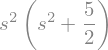

Expresión reescrita C + R/Q:


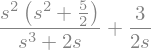

F resultante:


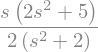

Próxima división:


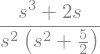

In [51]:
sp.init_printing()

s = sp.Symbol('s')

numerador =  3 + 4*s**2 + 1*s**4
denominador = 2*s + 1*s**3

cociente, residuo = cauer_division_dc(numerador, denominador)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Capacitor serie valor $\frac{2}{3}$;

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


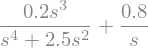

F resultante:


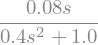

Próxima división:


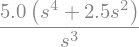

In [52]:
sp.init_printing()

s = sp.Symbol('s')

numerador =  2*s + 1*s**3
denominador = (5/2)*s**2 + 1*s**4

cociente, residuo = cauer_division_dc(numerador, denominador)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Inductor en derivación valor $\frac{1}{0.8}$ o $1.25$ o $\frac{5}{4}$;

Numerador:


Denominador:


cociente:


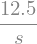

Residuo:


Expresión reescrita C + R/Q:


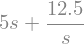

F resultante:


Próxima división:


In [54]:
sp.init_printing()

s = sp.Symbol('s')

numerador =  (2.5*5)*s**2 + 5*s**4
denominador = 1*s**3

cociente, residuo = cauer_division_dc(numerador, denominador)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print("Próxima división:")
display(denominador/residuo)

### Capacitor serie valor $\frac{1}{12.5}$ o $0.08$ o $\frac{2}{25}$;

In [58]:
sp.init_printing()

s = sp.Symbol('s')

numerador =  1
denominador = 5*s

cociente, residuo = cauer_division_dc(numerador, denominador)

print("Numerador:")
display(numerador)

print("Denominador:")
display(denominador)

print("cociente:")
display(cociente)

print("Residuo:")
display(residuo)

print("Expresión reescrita C + R/Q:")
display(cociente + residuo/denominador)


T = sp.simplify(numerador/denominador - cociente)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

Numerador:


Denominador:


cociente:


Residuo:


Expresión reescrita C + R/Q:


F resultante:


### Inductor en derivación valor $5$;

## Procedemos a realizar el método gráfico removiendo polos en cero/DC:

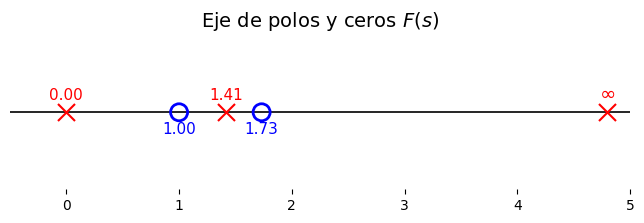

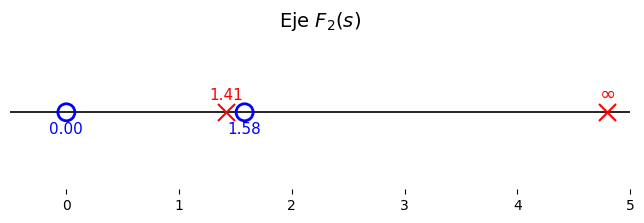

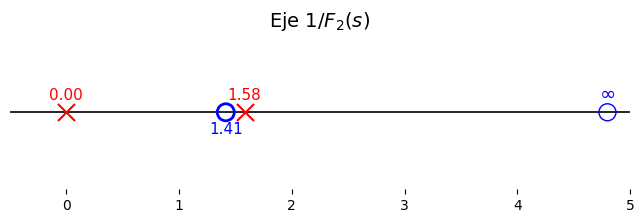

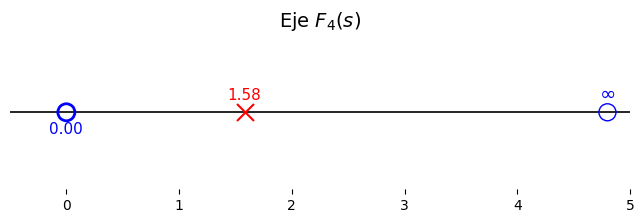

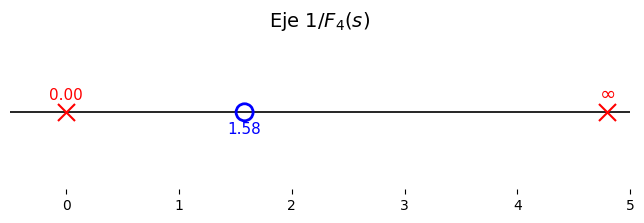

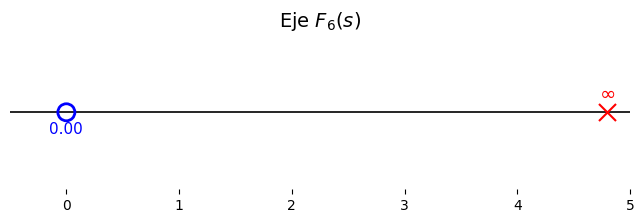

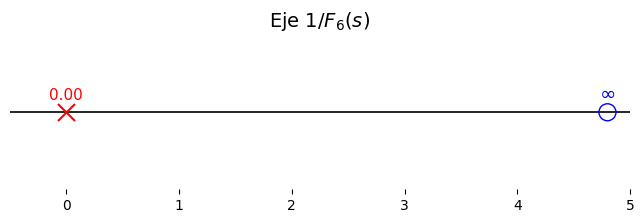

In [59]:
fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0, np.sqrt(2)]
ceros = [1, np.sqrt(3)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje de polos y ceros $F(s)$", fontsize=14)
plt.show()

##### eje 2: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [np.sqrt(2)]
ceros = [0, np.sqrt(5/2)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_2(s)$", fontsize=14)
plt.show()

##### eje 2 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [np.sqrt(2)]
polos = [0, np.sqrt(5/2)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_2(s)$", fontsize=14)
plt.show()

##### eje 4: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [0]
polos = [np.sqrt(1/0.4)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_4(s)$", fontsize=14)
plt.show()

##### eje 4 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0]
ceros = [np.sqrt(1/0.4)]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
##ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_4(s)$", fontsize=14)
plt.show()

##### eje 6: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

##polos = [0]
ceros = [0]

##ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

##for p in polos:
##    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
##ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje $F_6(s)$", fontsize=14)
plt.show()

##### eje 6 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0]
##ceros = [0]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
##ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
##for c in ceros:
##    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_6(s)$", fontsize=14)
plt.show()

### Topología circuital resultante:
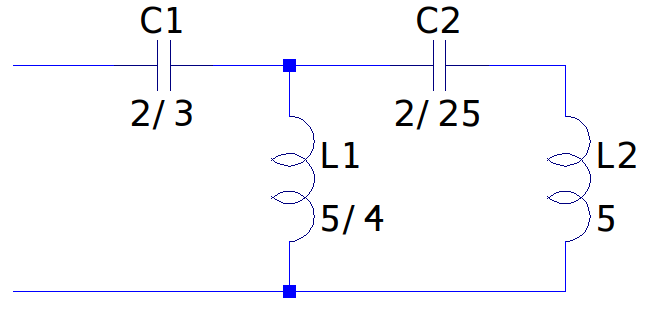

### Simulación observando fase y pendiente:
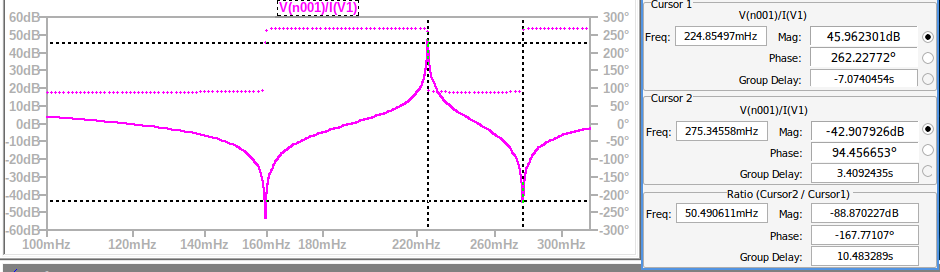

#### Por último se sigue observando el mismo comportamiento, siendo todas las síntesis equivalentes.

# Segunda parte:
## Esquematizar mapa de remociones mediante el método gráfico:
### Hallar valor de componentes que satisfaga:
$$
Y(s) = \frac{s^5 + 18 \ s^3 + 48 \ s}{6 \ s^4 + 42 \ s^2 + 48}
$$

#### equivalencia:

$$Y(s)=\frac{s\left(s^2+9-\sqrt{33}\right)\left(s^2+9+\sqrt{33}\right)}{6\left(s^2+\frac{7-\sqrt{17}}{2}\right)\left(s^2+\frac{7+\sqrt{17}}{2}\right)}$$

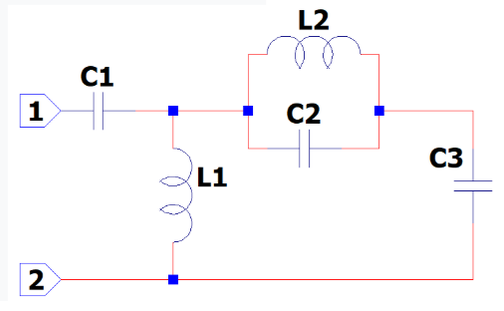

### Remociones método gráfico:
- Tenemos primero un capacitor en serie, implica remoción polo en 0/DC para Z
- Luego tenemos un inductor en derivación, implica remoción polo en 0/DC para Y
- Le sigue un tanque en serie, implica remoción en el medio de $\frac{2 \ k_i \ s}{s^2 + {\omega_i}^2}$ en serie para Z
- Por último un capacitor serie, implica remoción polo en 0/DC para Z

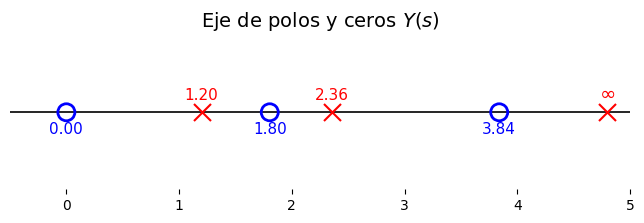

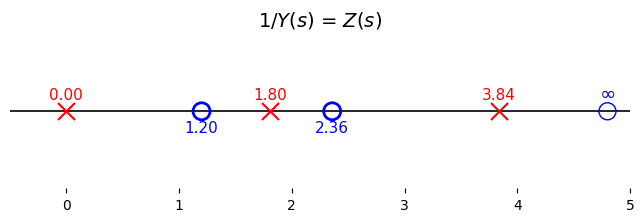

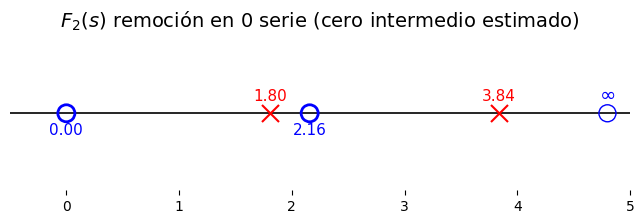

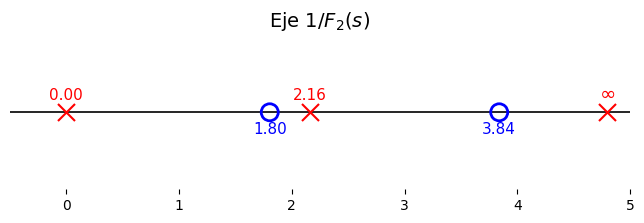

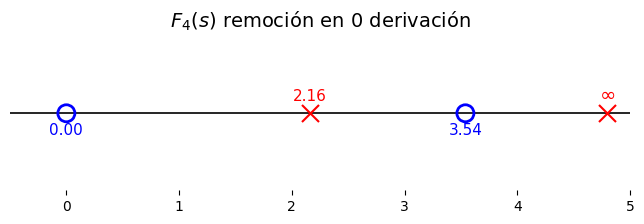

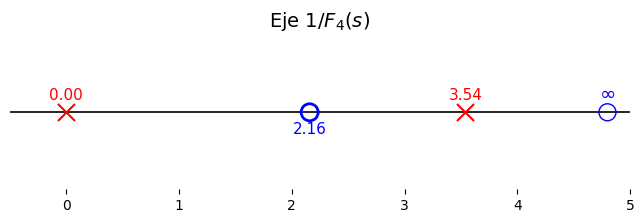

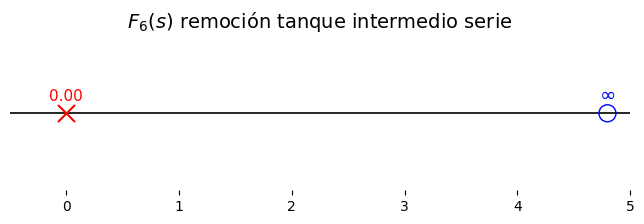

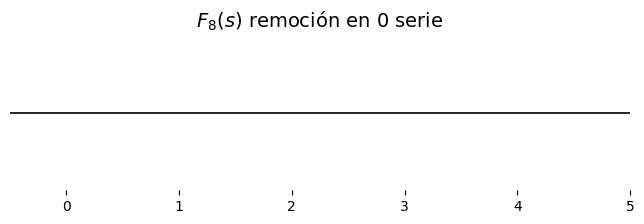

In [74]:
fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [np.sqrt((7-np.sqrt(17))/2), np.sqrt((7+np.sqrt(17))/2)]
ceros = [0, np.sqrt(9-np.sqrt(33)), np.sqrt(9+np.sqrt(33))]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje de polos y ceros $Y(s)$", fontsize=14)
plt.show()

######## Eje invertido 1/Y(s) = Z(s): #############

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [np.sqrt((7-np.sqrt(17))/2), np.sqrt((7+np.sqrt(17))/2)]
polos = [0, np.sqrt(9-np.sqrt(33)), np.sqrt(9+np.sqrt(33))]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("1/$Y(s)$ = $Z(s)$", fontsize=14)
plt.show()


##### eje 2: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [0, np.sqrt((7+np.sqrt(17))/2) -0.2]
polos = [np.sqrt(9-np.sqrt(33)), np.sqrt(9+np.sqrt(33))]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("$F_2(s)$ remoción en 0 serie (cero intermedio estimado)", fontsize=14)
plt.show()

##### eje 2 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [0, np.sqrt((7+np.sqrt(17))/2) -0.2]
ceros = [np.sqrt(9-np.sqrt(33)), np.sqrt(9+np.sqrt(33))]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
##ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_2(s)$", fontsize=14)
plt.show()

##### eje 4: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = [np.sqrt((7+np.sqrt(17))/2) -0.2]
ceros = [0, np.sqrt(9+np.sqrt(33))-0.3]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
##ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("$F_4(s)$ remoción en 0 derivación", fontsize=14)
plt.show()

##### eje 4 invertido: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = [np.sqrt((7+np.sqrt(17))/2) -0.2]
polos = [0, np.sqrt(9+np.sqrt(33))-0.3]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Eje 1/$F_4(s)$", fontsize=14)
plt.show()

##### eje 6: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

ceros = []
polos = [0]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("$F_6(s)$ remoción tanque intermedio serie", fontsize=14)
plt.show()

##### eje 8: #####

fig, ax = plt.subplots(figsize=(8,2))

ax.axhline(0, color='black', linewidth=1.2)

polos = []
ceros = []

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue',  s=150, linewidth=2, label='Ceros', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)

limite_derecho = 5.0
ax.set_xlim(-0.5, limite_derecho)

##ax.scatter(limite_derecho - 0.2, 0, marker='x', color='red', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold')
##ax.scatter(limite_derecho - 0.2, 0, marker='o', facecolors='none', edgecolors='blue', s=150, zorder=3)
##ax.text(limite_derecho - 0.2, 0.06, r'$\infty$', color='blue', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("$F_8(s)$ remoción en 0 serie", fontsize=14)
plt.show()

## Hallar valores de componentes:

$$
Z(s) = \frac{6 \ s^4 + 42 \ s^2 + 48}{s^5 + 18 \ s^3 + 48 \ s}
$$
### Equivalencia:
$$
Z(s)=\frac{6\left(s^2+\frac{7-\sqrt{17}}{2}\right)\left(s^2+\frac{7+\sqrt{17}}{2}\right)}{s\left(s^2+9-\sqrt{33}\right)\left(s^2+9+\sqrt{33}\right)}
$$

#### $F_1$ capacitor serie $\frac{K_0}{s}$:
$$
K_0 = lim_{s\rightarrow 0}\ s \cdot Z(s) = \frac{6\left(0+\frac{7-\sqrt{17}}{2}\right)\left(0+\frac{7+\sqrt{17}}{2}\right)}{\left(0+9-\sqrt{33}\right)\left(0+9+\sqrt{33}\right)} = 1
$$
### Capacitor valor 1;

### $F_2=Z(s)- F_1$:

F resultante:


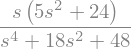

<IPython.core.display.Math object>

In [82]:
sp.init_printing()

s = sp.Symbol('s')

numerador1 =  6*s**4 + 42*s**2 + 48
denominador1 = s**5 + 18*s**3 + 48*s

numerador2 = 1
denominador2 = s


T = sp.simplify(numerador1/denominador1 - numerador2/denominador2)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print_latex(a_equal_b_latex_s('F_2', T))

### $F_3$ inductor en derivación $\frac{K_0}{s}$:

$$
K_0 = lim_{s\rightarrow 0}\ s \cdot \frac{1}{F_2(s)} = \frac{0+18\cdot0+48}{5\cdot0+24} = 2
$$
### Inductor valor $\frac{1}{2}$;

### $F_4=\frac{1}{F_2(s)}- F_3$:

F resultante:


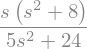

<IPython.core.display.Math object>

In [81]:
sp.init_printing()

s = sp.Symbol('s')

numerador1 =  s**4 + 18*s**2 + 48
denominador1 = 5*s**3 + 24*s

numerador2 = 2
denominador2 = s


T = sp.simplify(numerador1/denominador1 - numerador2/denominador2)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print_latex(a_equal_b_latex_s('F_4', T))

### $F_5$ tanque en serie $\frac{2 \ K_i \ s}{s^2+{\omega_i}^2}$:

$$
\frac{1}{F_4} = \frac{5 \ s^2 + 24}{s \ (s^2+8)} \rightarrow tanque \ en \ (s^2+8)
$$

$$
2 \ K_1 = lim_{s^2\rightarrow -8}\ \frac{s^2+8}{s} \cdot \frac{1}{F_4(s)} = \frac{5\cdot -8 + 24}{-8} = 2
$$

$$
\frac{2 \ k_1 \ s}{s^2+8} = \frac{1}{\frac{s}{2 \ k_1} + \frac{1}{s \cdot \frac{2 \ K_1}{8}}}
$$

### Capacitor del tanque: $\frac{1}{2 \ K_1} = \frac{1}{2}$
### Inductor del tanque: $\frac{2 \ K_1}{8} = \frac{1}{4}$

### $F_6=\frac{1}{F_4(s)}- F_5$:

In [84]:
sp.init_printing()

s = sp.Symbol('s')

numerador1 =  5*s**2 + 24
denominador1 = s**3 + 8*s

numerador2 = 2*s
denominador2 = s**2 + 8


T = sp.simplify(numerador1/denominador1 - numerador2/denominador2)
T = sp.together(T)
T = sp.factor(T)
T = sp.simplify(T)

print("F resultante:")
display(T)

print_latex(a_equal_b_latex_s('F_6', T))

F resultante:


<IPython.core.display.Math object>

### $F_7$ capacitor serie $\frac{K_0}{s}$:
$$
K_0 = lim_{s\rightarrow 0}\ \ s \cdot F_6(s) = 3
$$
### Capacitor valor $\frac{1}{3}$;

$$
F_8 = F_6 - F_7 = \frac{3}{s} - \frac{3}{s} = 0
$$

## Circuito final, valores:
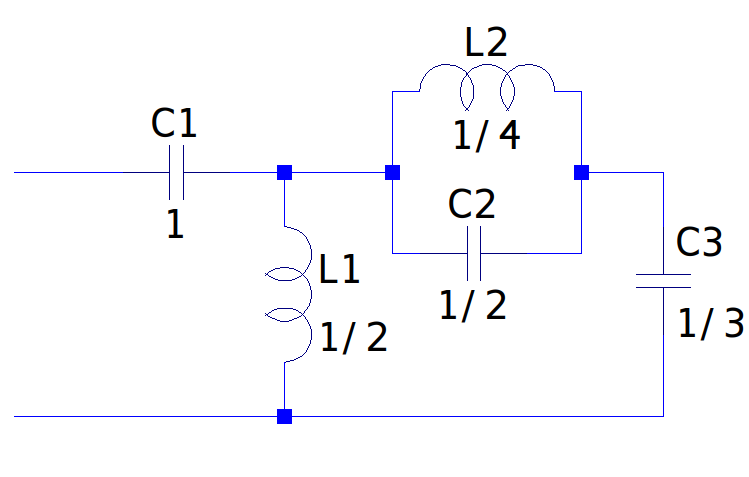

## Comparamos simulaciones para verificar:

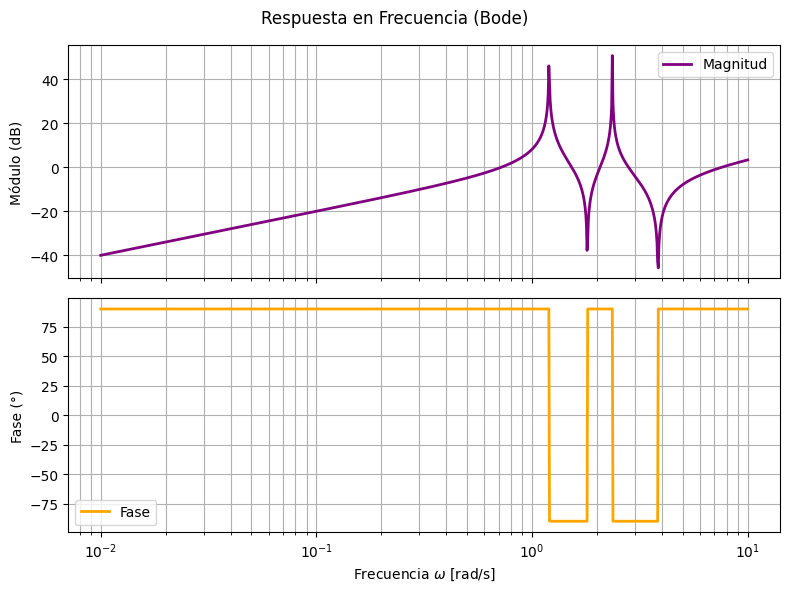

In [88]:
# Defino la transferencia
num = [1, 0, 18, 0, 48, 0]
den = [6, 0, 42, 0, 48]
H = sig.TransferFunction(num, den)

w = np.logspace(-2, 1, 1000)   # de 0.01 a 10 rad/s

w_bode, H_mag, H_phase = sig.bode(H, w=w)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.suptitle("Respuesta en Frecuencia (Bode)")

ax1.semilogx(w_bode, H_mag, color="purple", lw=2, label="Magnitud")
ax1.set_ylabel("Módulo (dB)")
ax1.grid(True, which="both")
ax1.legend()

ax2.semilogx(w_bode, H_phase, color="orange", lw=2, label="Fase")
ax2.set_ylabel("Fase (°)")
ax2.set_xlabel("Frecuencia $\omega$ [rad/s]")
ax2.grid(True, which="both")
ax2.legend()

plt.tight_layout()
plt.show()

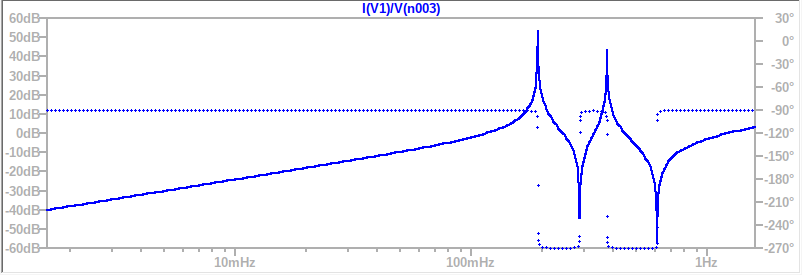

### Las simulaciones verifican el resultado